# Rendimiento estudiantil en exámenes: análisis exploratorio con pandas

**Student Performance in Exams** · Python, pandas, matplotlib y seaborn

Este conjunto de datos contiene información sobre el rendimiento de distintos estudiantes en tres exámenes y algunas características demográficas. El conjunto tiene las siguientes columnas:

- **gender**:
  - Indica el género del estudiante (*hombre* o *mujer*).
- **race/ethnicity**:
  - Agrupa a los estudiantes en cinco categorías.
- **parental level of education**:
  - Muestra el nivel educativo más alto alcanzado por los padres del estudiante.
    - *some high school*: Significa que el padre/madre asistió a la secundaria pero no la terminó.
    - *high school*: Terminaron la secundaria pero no continuaron con sus estudios.
    - *some college*: Asistieron a la universidad o una institución de educación superior, pero no la completaron.
    - *associate degree*: Es un título técnico o universitario de dos años (común en EE. UU.).
    - *bachelor degree*: Alguno de los padres obtuvo un título universitario.
    - *master degree*: Alguno de los padres obtuvo un título de posgrado (máster o maestría).
- **lunch**:
  - Indica el tipo de almuerzo que recibe el estudiante.
    - *standard*: Almuerzo de pago estándar.
    - *free/reduced*: Almuerzo gratuito o con descuento.
- **test preparation course**:
  - Indica si el estudiante completó un curso de preparación antes del examen.
- **math score**:
  - Puntaje obtenido por el estudiante en matemáticas.
- **reading score**:
  - Puntaje obtenido por el estudiante en lectura.
- **writing score**:
  - Puntaje obtenido por el estudiante en escritura.

> **Nota sobre los datos:** este es un dataset de uso educativo muy difundido y suele describirse como ficticio (confirma la fuente en la página de descarga). Los resultados sirven para practicar análisis de datos, no para sacar conclusiones sobre estudiantes reales.

## Preguntas que quiero responder

1. ¿Se asocia el curso de preparación con mejores notas?
2. ¿Qué diferencia hay según el tipo de almuerzo (un indicador indirecto del nivel socioeconómico)?
3. ¿Cómo cambian las notas con el nivel educativo de los padres?
4. ¿Hay diferencias por género en cada materia?
5. ¿Y entre los grupos étnicos (anonimizados como A a E)?
6. ¿Cómo se combinan el curso de preparación y el tipo de almuerzo?
7. ¿Qué proporción de estudiantes reprueba (promedio menor a 60) según cada factor?
8. ¿Qué tan relacionadas están las tres materias entre sí?
9. ¿Hay valores atípicos?
10. ¿En qué se diferencian el 10% de estudiantes con mejores notas y el 10% con peores?

> **Importante al interpretar:** los resultados muestran **asociaciones, no causas**. El género y el grupo étnico son variables sensibles y se describen sin generalizar.

## 1. Carga y revisión de los datos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")

IMG = Path("../images")
IMG.mkdir(exist_ok=True)

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", dpi=150, bbox_inches="tight")

In [ ]:
data = pd.read_csv("../data/StudentsPerformance.csv")

In [6]:
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
data.shape

(1000, 8)

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [9]:
data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [10]:
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [11]:
data.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [12]:
# ¿Hay filas duplicadas?
print("Filas duplicadas:", data.duplicated().sum())

Filas duplicadas: 0


**Calidad de los datos:** 1,000 filas y 8 columnas, sin valores nulos ni filas duplicadas. No hace falta limpieza; más adelante se revisan los valores atípicos.

## 2. Exploración inicial

In [13]:
data[['math score', 'reading score',
       'writing score']].agg(["mean", "median", "std"])

,math score,reading score,writing score
mean,66.08900,69.169000,68.054000
median,66.00000,70.000000,69.000000
std,15.16308,14.600192,15.195657


In [14]:
data["gender"].value_counts()

gender
female    518
male      482
Name: count, dtype: int64

In [15]:
data['parental level of education'].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [16]:
data["lunch"].value_counts()

lunch
standard        645
free/reduced    355
Name: count, dtype: int64

In [17]:
data[['gender', 'parental level of education', 'lunch']].value_counts()

gender  parental level of education  lunch       
female  associate's degree           standard        80
        some college                 standard        74
male    some college                 standard        73
        high school                  standard        69
        associate's degree           standard        65
        some high school             standard        63
female  high school                  standard        57
        some high school             standard        55
        some college                 free/reduced    44
        bachelor's degree            standard        41
male    associate's degree           free/reduced    41
female  high school                  free/reduced    37
        some high school             free/reduced    36
        associate's degree           free/reduced    36
male    some college                 free/reduced    35
        high school                  free/reduced    33
        bachelor's degree            standard        3

## 3. Preparación de los datos

Se crean tres columnas nuevas:
- `promedio`: promedio de las tres notas.
- `categoria`: letra de A a F según el promedio (escala supuesta: A ≥ 90, B ≥ 80, C ≥ 70, D ≥ 60, F < 60).
- `reprobado`: `True` si el promedio es menor a 60 (categoría F).

In [18]:
data["promedio"] = data[['math score', 'reading score', 'writing score']].mean(axis=1).round(2)
data.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,promedio
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67
1,female,group C,some college,standard,completed,69,90,88,82.33
2,female,group B,master's degree,standard,none,90,95,93,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33
4,male,group C,some college,standard,none,76,78,75,76.33


In [19]:
def categoria_cal(promedio):
    if promedio >= 90:
        return "A"
    elif promedio >= 80:
        return "B"
    elif promedio >= 70:
        return "C"
    elif promedio >= 60:
        return "D"
    else:
        return "F"

data["categoria"] = data["promedio"].apply(categoria_cal)
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,promedio,categoria
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,C
1,female,group C,some college,standard,completed,69,90,88,82.33,B
2,female,group B,master's degree,standard,none,90,95,93,92.67,A
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,F
4,male,group C,some college,standard,none,76,78,75,76.33,C


In [20]:
data["categoria"].value_counts()

categoria
F    285
C    261
D    256
B    146
A     52
Name: count, dtype: int64

In [21]:
NOTAS = ["math score", "reading score", "writing score"]

data["reprobado"] = data["categoria"] == "F"   # promedio menor a 60
print(f"Proporción de reprobados: {data['reprobado'].mean():.1%}")

Proporción de reprobados: 28.5%


## 4. Distribución de las notas

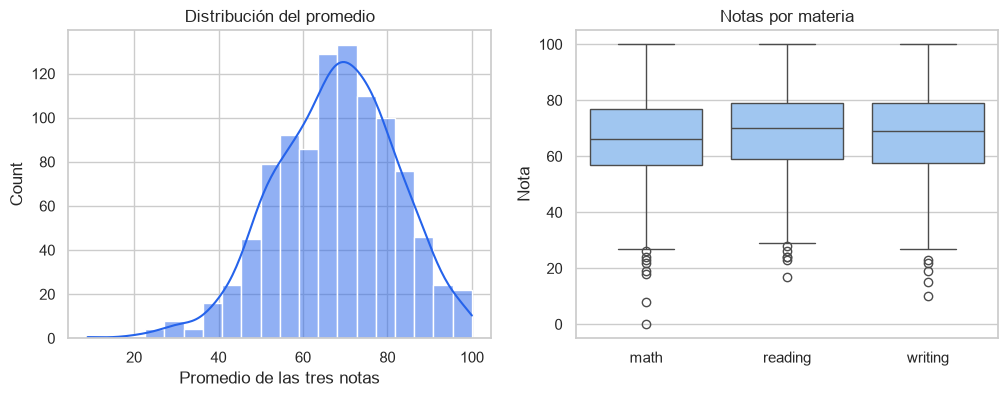

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data["promedio"], bins=20, kde=True, ax=axes[0], color="#2563EB")
axes[0].set_title("Distribución del promedio")
axes[0].set_xlabel("Promedio de las tres notas")

notas = data[NOTAS].rename(columns=lambda c: c.replace(" score", ""))
sns.boxplot(data=notas, ax=axes[1], color="#93C5FD")
axes[1].set_title("Notas por materia")
axes[1].set_ylabel("Nota")

guardar("01_distribucion_notas")
plt.show()

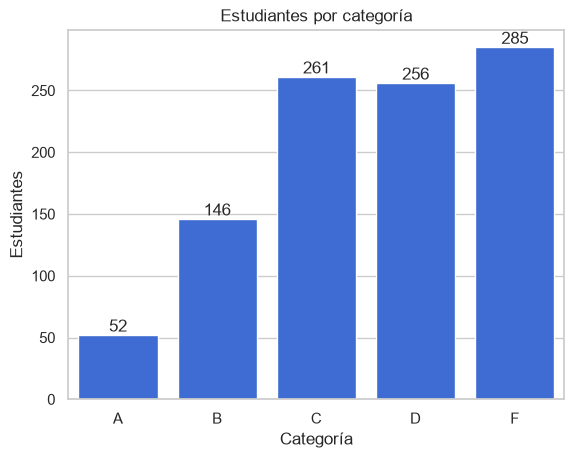

In [23]:
ax = sns.countplot(data=data, x="categoria", order=["A", "B", "C", "D", "F"], color="#2563EB")
ax.bar_label(ax.containers[0])
ax.set_title("Estudiantes por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Estudiantes")

guardar("02_categorias")
plt.show()

## 5. Funciones auxiliares

Para comparar dos grupos se calculan tres cosas:
- la **diferencia de medias**,
- el **tamaño del efecto (d de Cohen)**: cerca de 0.2 es pequeño, 0.5 moderado y 0.8 grande,
- el **p-valor** de una prueba t de Welch, que indica si la diferencia podría deberse al azar.

In [46]:
def cohen_d(a, b):
    """Tamaño del efecto entre dos grupos."""
    n1, n2 = len(a), len(b)
    sp = (((n1 - 1) * a.var() + (n2 - 1) * b.var()) / (n1 + n2 - 2)) ** 0.5
    return (a.mean() - b.mean()) / sp


def comparar(columna, grupo1, grupo2):
    """Compara las notas de dos grupos de una columna categórica."""
    g1 = data[data[columna] == grupo1]
    g2 = data[data[columna] == grupo2]
    filas = []
    for nota in NOTAS + ["promedio"]:
        a, b = g1[nota], g2[nota]
        p = stats.ttest_ind(a, b, equal_var=False).pvalue
        filas.append({
            "materia": nota,
            f"media {grupo1}": a.mean(),
            f"media {grupo2}": b.mean(),
            "diferencia": a.mean() - b.mean(),
            "d de Cohen": cohen_d(a, b),
            "p-valor": "< 0.001" if p < 0.001 else f"{p:.3f}",
        })
    return pd.DataFrame(filas).set_index("materia").round(2)


def barras_por_materia(columna, titulo, nombre):
    """Barras con la nota promedio de cada materia, separada por grupo."""
    medias = data.groupby(columna)[NOTAS].mean().T
    medias.index = ["Matemáticas", "Lectura", "Escritura"]
    ax = medias.plot(kind="bar", figsize=(7, 4), rot=0, width=0.75)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f", padding=2, fontsize=9)
    ax.set_title(titulo)
    ax.set_ylabel("Nota promedio")
    ax.set_ylim(0, 85)
    ax.legend(title=columna, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
    ax.grid(axis="x", visible=False)
    guardar(nombre)
    plt.show()

## 6. Análisis por pregunta

### Pregunta 1: ¿Se asocia el curso de preparación con mejores notas?

In [25]:
comparar("test preparation course", "completed", "none")

,media completed,media none,diferencia,d de Cohen,p-valor
materia,,,,,
math score,69.70,64.08,5.62,0.38,< 0.001
reading score,73.89,66.53,7.36,0.52,< 0.001
writing score,74.42,64.50,9.91,0.69,< 0.001
promedio,72.67,65.04,7.63,0.55,< 0.001


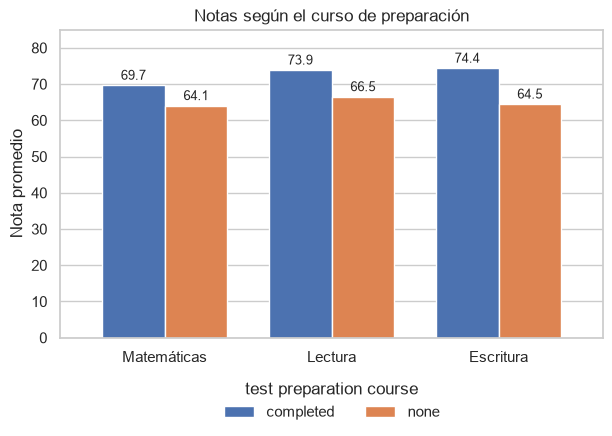

In [26]:
barras_por_materia("test preparation course", "Notas según el curso de preparación", "03_curso_preparacion")

**Conclusión:** quienes completaron el curso tienen un promedio 7.6 puntos más alto (72.7 frente a 65.0), con un efecto moderado (d ≈ 0.55). La diferencia es mayor en escritura (+9.9) y menor en matemáticas (+5.6). Es una asociación: no se puede afirmar que el curso cause la mejora.

### Pregunta 2: ¿Qué diferencia hay según el tipo de almuerzo?

In [27]:
comparar("lunch", "standard", "free/reduced")

,media standard,media free/reduced,diferencia,d de Cohen,p-valor
materia,,,,,
math score,70.03,58.92,11.11,0.78,< 0.001
reading score,71.65,64.65,7.00,0.49,< 0.001
writing score,70.82,63.02,7.80,0.53,< 0.001
promedio,70.84,62.20,8.64,0.63,< 0.001


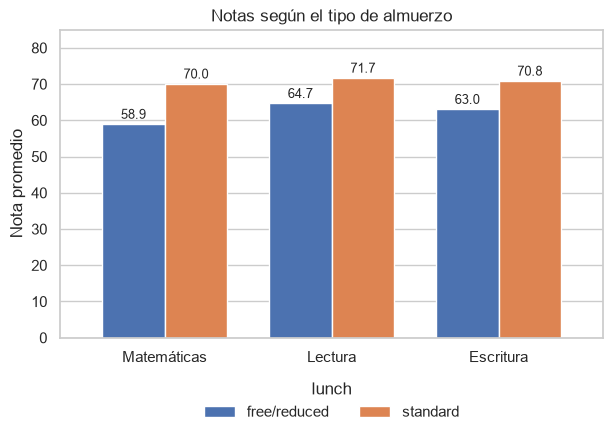

In [28]:
barras_por_materia("lunch", "Notas según el tipo de almuerzo", "04_almuerzo")

**Conclusión:** los estudiantes con almuerzo estándar promedian 70.8 y los de almuerzo gratuito o reducido, 62.2 (+8.6, d ≈ 0.63). La brecha es la mayor de las tres variables y se concentra en matemáticas (+11.1). El almuerzo es un indicador indirecto del nivel socioeconómico, no una medida directa.

### Pregunta 3: ¿Cómo cambian las notas con la educación de los padres?

In [29]:
data.groupby("parental level of education")[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


In [30]:
ORDEN_EDU = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]

edu = (data.groupby("parental level of education")["promedio"]
           .agg(["mean", "count"])
           .reindex(ORDEN_EDU)
           .round(1))
edu

,mean,count
parental level of education,,
some high school,65.1,179
high school,63.1,196
some college,68.5,226
associate's degree,69.6,222
bachelor's degree,71.9,118
master's degree,73.6,59


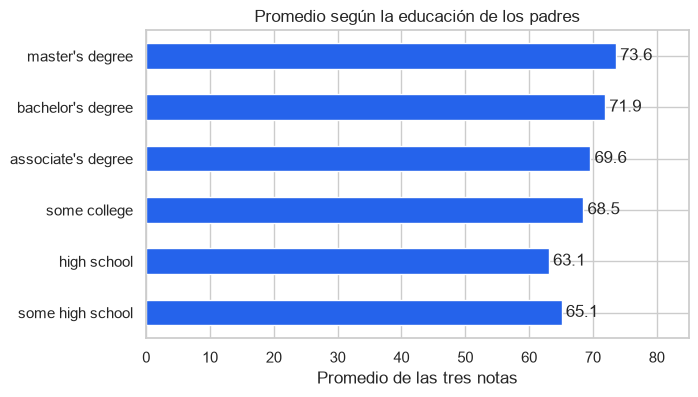

In [31]:
ax = edu["mean"].plot(kind="barh", figsize=(7, 4), color="#2563EB")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Promedio según la educación de los padres")
ax.set_xlabel("Promedio de las tres notas")
ax.set_ylabel("")
ax.set_xlim(0, 85)

guardar("05_educacion_padres")
plt.show()

**Conclusión:** el promedio sube de 63.1 (padres con secundaria completa) a 73.6 (maestría). La tendencia general es creciente, pero no estrictamente: "some high school" (65.1) queda por encima de "high school" (63.1). El grupo de maestría es el más pequeño (59 estudiantes), así que su promedio es menos estable.

### Pregunta 4: ¿Hay diferencias por género en cada materia?

In [32]:
data.groupby("gender")[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


In [33]:
comparar("gender", "female", "male")

,media female,media male,diferencia,d de Cohen,p-valor
materia,,,,,
math score,63.63,68.73,-5.10,-0.34,< 0.001
reading score,72.61,65.47,7.14,0.50,< 0.001
writing score,72.47,63.31,9.16,0.63,< 0.001
promedio,69.57,65.84,3.73,0.26,< 0.001


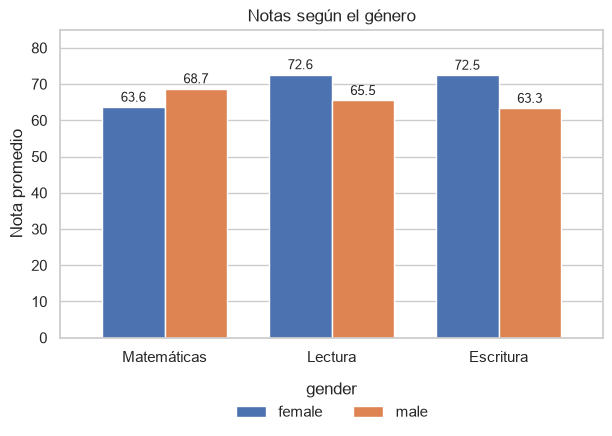

In [34]:
barras_por_materia("gender", "Notas según el género", "06_genero")

**Conclusión:** el patrón cambia según la materia. Las mujeres puntúan más alto en lectura (+7.1) y escritura (+9.2), y los hombres en matemáticas (+5.1). En el promedio general, las mujeres superan a los hombres por 3.7 puntos (efecto pequeño, d ≈ 0.26).

### Pregunta 5: ¿Y entre los grupos étnicos?

Los grupos aparecen anonimizados (A a E) y no se conoce su significado, por lo que se describen solo las cifras.

In [35]:
grupos = (data.groupby("race/ethnicity")["promedio"]
              .agg(["mean", "count"])
              .round(1))
grupos

,mean,count
race/ethnicity,,
group A,63.0,89
group B,65.5,190
group C,67.1,319
group D,69.2,262
group E,72.8,140


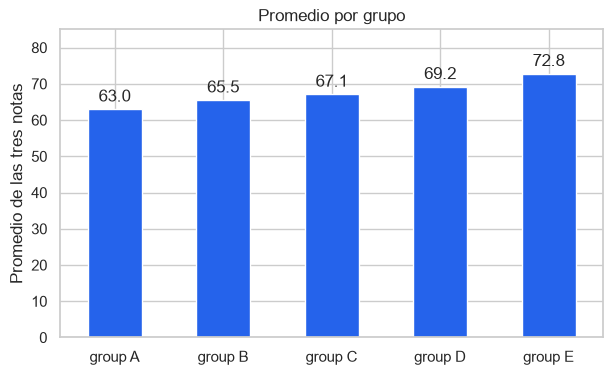

In [36]:
ax = grupos["mean"].plot(kind="bar", figsize=(7, 4), rot=0, color="#2563EB")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Promedio por grupo")
ax.set_xlabel("")
ax.set_ylabel("Promedio de las tres notas")
ax.set_ylim(0, 85)

guardar("07_grupos")
plt.show()

**Conclusión:** los promedios van de 63.0 (grupo A) a 72.8 (grupo E). Los tamaños de grupo son muy distintos (de 89 a 319 estudiantes), y sin más contexto no hay base para explicar la diferencia.

### Pregunta 6: ¿Cómo se combinan el curso de preparación y el tipo de almuerzo?

In [37]:
tabla = data.pivot_table(values="promedio", index="lunch",
                         columns="test preparation course", aggfunc="mean").round(1)
tabla

test preparation course,completed,none
lunch,,
free/reduced,67.8,58.9
standard,75.5,68.3


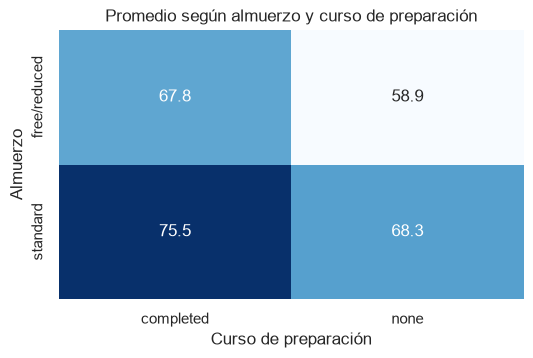

In [38]:
plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="Blues", cbar=False)
plt.title("Promedio según almuerzo y curso de preparación")
plt.xlabel("Curso de preparación")
plt.ylabel("Almuerzo")

guardar("08_almuerzo_y_curso")
plt.show()

**Conclusión:** ambos factores se suman. El promedio va de 58.9 (almuerzo gratuito y sin curso) a 75.5 (almuerzo estándar y con curso). Los estudiantes con almuerzo gratuito que completaron el curso (67.8) quedan casi al nivel de quienes tienen almuerzo estándar y no lo hicieron (68.3).

### Pregunta 7: ¿Qué proporción reprueba según cada factor?

Se considera reprobado un promedio menor a 60 (categoría F).

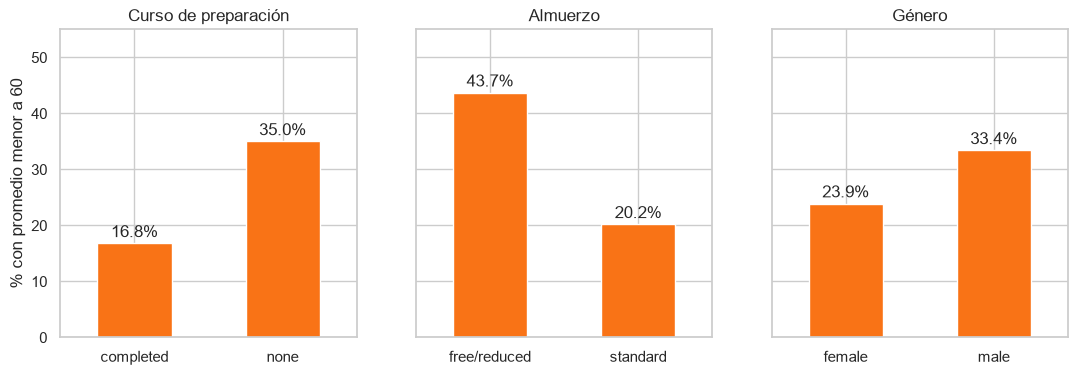

In [39]:
factores = {
    "test preparation course": "Curso de preparación",
    "lunch": "Almuerzo",
    "gender": "Género",
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, titulo) in zip(axes, factores.items()):
    tasa = data.groupby(col)["reprobado"].mean().mul(100).round(1)
    tasa.plot(kind="bar", ax=ax, rot=0, color="#F97316")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(titulo)
    ax.set_xlabel("")
axes[0].set_ylabel("% con promedio menor a 60")
axes[0].set_ylim(0, 55)

guardar("09_reprobacion")
plt.show()

**Conclusión:** el porcentaje de estudiantes con promedio menor a 60 es de 35.0% sin curso y 16.8% con curso; 43.7% con almuerzo gratuito y 20.2% con estándar; y 33.4% en hombres frente a 23.9% en mujeres.

### Pregunta 8: ¿Qué tan relacionadas están las materias?

In [40]:
data[['math score', 'reading score', 'writing score']].corr()

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


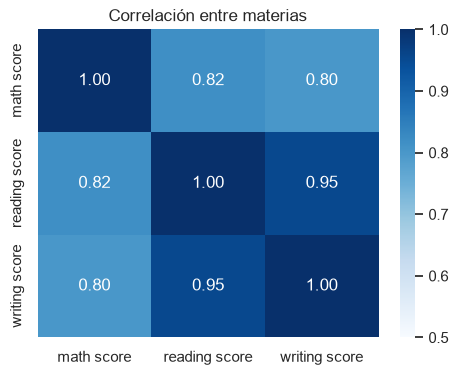

In [41]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(data[NOTAS].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0.5, vmax=1)
plt.title("Correlación entre materias")

guardar("10_correlacion")
plt.show()

**Conclusión:** lectura y escritura están casi superpuestas (0.95), y matemáticas se relaciona con ambas de forma fuerte pero menor (0.80 a 0.82). Quien rinde bien en una materia tiende a rendir bien en las otras.

### Pregunta 9: ¿Hay valores atípicos?

In [42]:
def atipicos_iqr(serie):
    """Valores fuera de 1.5 veces el rango intercuartílico."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return serie[(serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)]

for nota in NOTAS:
    print(f"{nota}: {len(atipicos_iqr(data[nota]))} valores atípicos")

data.nsmallest(5, "math score")[NOTAS + ["promedio"]]

math score: 8 valores atípicos
reading score: 6 valores atípicos
writing score: 5 valores atípicos


,math score,reading score,writing score,promedio
59,0,17,10,9.00
980,8,24,23,18.33
17,18,32,28,26.00
787,19,38,32,29.67
145,22,39,33,31.33


**Conclusión:** hay entre 5 y 8 valores atípicos por materia, todos en el extremo bajo. El caso más llamativo es un estudiante con 0 en matemáticas y notas muy bajas en las otras dos (17 y 10). No hay forma de saber si es un error de captura o un dato real, así que **se conservan** y se deja constancia.

### Pregunta 10: ¿En qué se diferencian el 10% mejor y el 10% peor?

In [43]:
mejor = data[data["promedio"] >= data["promedio"].quantile(0.9)]
peor = data[data["promedio"] <= data["promedio"].quantile(0.1)]

def perfil(grupo):
    return {
        "curso completado (%)": (grupo["test preparation course"] == "completed").mean() * 100,
        "almuerzo estándar (%)": (grupo["lunch"] == "standard").mean() * 100,
        "padres con licenciatura o más (%)": grupo["parental level of education"]
            .isin(["bachelor's degree", "master's degree"]).mean() * 100,
        "mujeres (%)": (grupo["gender"] == "female").mean() * 100,
    }

pd.DataFrame({"10% peor": perfil(peor),
              "10% mejor": perfil(mejor),
              "Todos": perfil(data)}).round(1)

,10% peor,10% mejor,Todos
curso completado (%),18.0,56.9,35.8
almuerzo estándar (%),40.0,87.3,64.5
padres con licenciatura o más (%),9.0,34.3,17.7
mujeres (%),38.0,66.7,51.8


**Conclusión:** entre el 10% con mejores notas, el 56.9% completó el curso, el 87.3% tiene almuerzo estándar y el 34.3% tiene padres con licenciatura o más. Entre el 10% con peores notas, esos porcentajes son 18.0%, 40.0% y 9.0%. El grupo de mejores notas tiene también más mujeres (66.7% frente a 38.0%).

## 7. Conclusiones

- **Curso de preparación, nivel socioeconómico y educación de los padres** se asocian con mejores notas. El almuerzo es el factor con mayor brecha (+8.6 puntos de promedio), seguido por el curso (+7.6).
- **Los factores se suman:** los estudiantes con almuerzo gratuito que hicieron el curso (67.8) llegan casi al nivel de quienes tienen almuerzo estándar y no lo hicieron (68.3).
- **El género muestra un patrón por materia:** las mujeres destacan en lectura y escritura, y los hombres en matemáticas.
- **Las materias están muy relacionadas**, sobre todo lectura y escritura (0.95).
- La proporción de estudiantes con promedio menor a 60 es más del doble sin curso (35.0%) que con curso (16.8%).

## 8. Limitaciones

- Son **asociaciones, no causas**: los datos no permiten decir que el curso o el almuerzo provoquen las diferencias.
- El dataset es **pequeño (1,000 estudiantes) y se describe como ficticio**, por lo que no se pueden generalizar los resultados.
- No hay información sobre el contexto de las variables (por ejemplo, qué representan los grupos A a E).
- Las categorías A-F usan una escala supuesta, no la de una institución real.